# Eigenvalues and Eigenvectors

In [101]:
import numpy as np
import scipy.linalg as sla
import numpy.linalg as la
import random
import matplotlib.pyplot as plt
%matplotlib inline

# I Eigenvalue problem

## Eigenvalue problem

Let $A$ be an $n\times n$ matrix:
$x \neq 0$ is an eigenvector of $A$ if there exists a scalar $\lambda$ such that
$$
A x = \lambda x
$$
where $\lambda$ is called an eigenvalue.  
If $x$ is an eigenvector, then $\alpha x$ is also an eigenvector. Therefore, we will usually seek for normalized eigenvectors, so that
$$
\|x\|_p = 1
$$
Note: When using Python, numpy.linalg.eig will normalize using $p=2$ norm

## How do we find eigenvalues?

Linear algebra approach:  
$$
A x = \lambda x
\\
(A - \lambda I) x = \bf{0}
$$
Therefore the matrix $(A - \lambda I)$ is singular $\Rightarrow \boxed{det(A - \lambda I) = 0}$  
$p(\lambda) = det(A - \lambda I)$ is the characteristic polynomial of degree $n$.  

In most cases, there is no analytical formula for the eigenvalues of a matrix (Abel proved in 1824 that there can be no formula for the roots of a polynomial of degree 5 or higher) $\Rightarrow$ Approximate the
eigenvalues numerically!

<details>
<summary>Example</summary>

$$
A = 
\begin{pmatrix}
2 & 1\\
4 & 2
\end{pmatrix}
\\
\Rightarrow
p(\lambda) = det(A - \lambda I) = (2 - \lambda)(2 - \lambda) - 4 = \lambda^2 - 4\lambda = \lambda(\lambda - 4)
\\
\Rightarrow
\lambda _1 = 0, \lambda _2 = 4
$$

</details>

In [102]:
A = np.array([
    [2, 1],
    [4, 2]
])
eigenvalues, eigenvectors = la.eig(A)
print(eigenvalues)
print(eigenvectors) # the eigenvectors give by la have norms=1 by default

[4.+0.j 0.+0.j]
[[ 0.4472136 +0.j -0.4472136 +0.j]
 [ 0.89442719+0.j  0.89442719+0.j]]


# II Diagonalizable Matrix

A $n \times n$ matrix $A$ with $n$ linearly independent eigenvectors $\bf{u}$ is said to be diagonalizable.

$$
\begin{aligned}
A \bf{u_1} = \lambda \bf{u_1} \\
A \bf{u_2} = \lambda \bf{u_2} \\
\vdots \\
A \bf{u_n} = \lambda \bf{u_n} \\
\end{aligned}
$$

$$
\Rightarrow 
\begin{bmatrix} A \end{bmatrix}
\begin{bmatrix}
| & | & & | \\
\mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
=
\begin{bmatrix}
| & | & & | \\
\lambda \mathbf{u}_1 & \lambda \mathbf{u}_2 & \cdots & \lambda \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
$$

$$
=
\begin{bmatrix}
| & | & & | \\
\mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
\begin{bmatrix}
\lambda_1    \\
  & \lambda_2   \\
 & & \ddots &  \\
  &   &  & \lambda_n
\end{bmatrix}
$$

If $A$ has $n$ linearly independent eigenvectors, then $U$ is full rank. Therefore, we can have
$$
A = UDU^{-1}
$$

<details>
<summary>Example</summary>

$$
A = 
\begin{pmatrix}
2 & 1\\
4 & 2
\end{pmatrix}
\\
\lambda _1 = 0, \lambda _2 = 4
x_1 = \begin{pmatrix}0.447\\0.894\end{pmatrix}, x_2 = \begin{pmatrix}-0.447\\0.894\end{pmatrix}
$$
then
$$
U = 
\begin{pmatrix}
0.447 & -0.447\\
0.894 & 0.894
\end{pmatrix} \\
D = 
\begin{pmatrix}
4 & 0\\
0 & 0
\end{pmatrix}
$$

</details>

In [103]:
eigenvalues, U = la.eig(A)

D = np.diag(eigenvalues)
U_inv = np.linalg.inv(U)

print("U =\n", U)
print("D =\n", D)
print("U^-1 =\n", U_inv)

print(np.allclose(A, U @ D @ U_inv))  # True

U =
 [[ 0.4472136 +0.j -0.4472136 +0.j]
 [ 0.89442719+0.j  0.89442719+0.j]]
D =
 [[4.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
U^-1 =
 [[ 1.11803399+0.j  0.55901699+0.j]
 [-1.11803399+0.j  0.55901699+0.j]]
True


1) If a $n \times n$ matrix $A$ has $n$ linearly independent eigenvectors $\bf{x}$ then $A$ is
diagonalizable, i.e., $A = UDU^{-1}$  
where the columns of $U$ are the linearly independent normalized eigenvectors $\bf{x}$ of $A$ (which guarantees that $U^{-1}$ exists) and $D$ is a diagonal
matrix with the eigenvalues of $A$.
2) If a $n \times n$ matrix $A$ has less then $n$ linearly independent eigenvectors, the
matrix is called **defective** (and therefore not diagonalizable).
3) If a $n \times n$ **symmetric** matrix $A$ has $n$ distinct eigenvalues then $A$ is
diagonalizable.

Proof:

Suppose $\lambda, \mathbf{u}$ and $\mu, \mathbf{v}$ are eigenpairs of $A$ with $\lambda \ne \mu$.



Since $A$ is symmetric, $A^T=A$. Then
$$
\lambda \mathbf{u}^T\mathbf{v}
=(A\mathbf{u})^T\mathbf{v}
=\mathbf{u}^TA^T\mathbf{v}
=\mathbf{u}^TA\mathbf{v}
=\mu\mathbf{u}^T\mathbf{v}.
$$

Therefore,
$$
(\lambda-\mu)\mathbf{u}^T\mathbf{v}=0.
$$

Since $\lambda\ne\mu$, we have
$$
\mathbf{u}^T\mathbf{v}=0.
$$

Thus, eigenvectors corresponding to distinct eigenvalues are orthogonal.

Since $A$ has $n$ distinct eigenvalues, it has $n$ linearly independent eigenvectors. Therefore, $A$ is diagonalizable.

Some things to remember about eigenvalues:  
• Eigenvalues can have zero value  
• Eigenvalues can be negative  
• Eigenvalues can be real or complex numbers  
• A $n \times n$ real matrix can have complex eigenvalues  
• The eigenvalues of a $n \times n$ matrix are not necessarily unique. In fact, we can define the multiplicity of an eigenvalue.  
• If a $n \times n$ matrix has $n$ linearly independent eigenvectors, then the matrix is diagonalizable  

# III Obtaining eigenvalues and eigenvectors numerically

## Power iteration

Assume that $A$ is diagonalizable (i.e., it has $n$ linearly independent eigenvectors $\bf{u}$). We can propose a vector $\bf{x}$ which is a linear combination of these eigenvectors:  
$$
\begin{aligned}
\bf{x} 
= 
\alpha _1 \bf{u}_1 + \alpha _2 \bf{u}_2 + \cdots + \alpha _n \bf{u}_n  
\\
\Rightarrow
\bf{A} \bf{x} 
= 
\bf{A} \alpha _1 \bf{u}_1 + \bf{A} \alpha _2 \bf{u}_2 + \cdots + \bf{A} \alpha _n \bf{u}_n  \\
= 
\alpha _1 \lambda _1 \bf{u}_1 + \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \alpha _n \lambda _n \bf{u}_n  \\
\end{aligned}
$$
Assume: $|\lambda _1| > |\lambda _2| \geq |\lambda _3| \geq \cdots \geq |\lambda _n|$


Our goal is to find an eigenvector $\bf{u_i}$ of $A$. We will use an iterative process, where we start with an initial vector, where here we assume that it can be written as a linear combination of the eigenvectors of $A$.
$$
\bf{x}_0 
= 
\alpha _1 \bf{u}_1 + \alpha _2 \bf{u}_2 + \cdots + \alpha _n \bf{u}_n  
$$

$$
\Rightarrow
\bf{A} \bf{x}_0
= 
\alpha _1 \lambda _1 \bf{u}_1 + \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \alpha _n \lambda _n \bf{u}_n
=
\bf{x}_1
$$

$$
\Rightarrow
\bf{A} \bf{x}_1
= 
\bf{A} \alpha _1 \lambda _1 \bf{u}_1 + \bf{A} \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \bf{A} \alpha _n \lambda _n \bf{u}_n
=
\alpha _1 \lambda _1 ^2 \bf{u}_1 + \alpha _2 \lambda _2 ^2 \bf{u}_2 + \cdots + \alpha _n \lambda _n ^2 \bf{u}_n
=
\bf{x}_2
$$

$$
\bf{A} \bf{x}_2
=
\alpha _1 \lambda _1 ^3 \bf{u}_1 + \alpha _2 \lambda _2 ^3 \bf{u}_2 + \cdots + \alpha _n \lambda _n ^3 \bf{u}_n
=
\bf{x}_3
$$

$$
\cdots \\
\bf{A} \bf{x}_{k-1}
=
\alpha _1 \lambda _1 ^k \bf{u}_1 + \alpha _2 \lambda _2 ^k \bf{u}_2 + \cdots + \alpha _n \lambda _n ^k \bf{u}_n
=
\bf{x}_k
$$

or
$$
\bf{x}_k
=
(\lambda _1)^k [\alpha _1 \bf{u}_1 + \alpha _2 \frac{\lambda _2}{{\lambda _1}} ^k \bf{u}_2 + \cdots + \alpha _n \frac{\lambda _n}{{\lambda _1}} ^k \bf{u}_n]
$$
Assume that $\alpha _1 \neq 0$, the term $\alpha _1 \bf{u}_1$ dominates the others when $k$ is
very large.  
Since $|\lambda _1| > |\lambda _2|$, we have $(\frac{\lambda _2}{\lambda _1})^k \ll 1$ when $k$ is
very large.  
Hence, as $k$ increases, $\bf{x}_k$ converges to a multiple of the first eigenvector $\bf{u}_1$, i.e., 
$$
k \to \infty, \bf{x}_k \to (\lambda _1)^k \alpha _1 \bf{u}_1
$$

## Try it in python

We want to prepare a matrix with deliberately chosen eigenvalues. Let's use diagonalization to write the matrix $\mathbf{A}$:

$$ \mathbf{A} = \mathbf{U D U}^{-1} $$

where we set ${\bf D}$ to be a known matrix with the pre-defined eigenvalues:

```python
D = np.diag([lambda1, lambda2, ..., lambdan])
```

We need to generate a matrix $\mathbf{U}$ that has an inverse. Orthogonal matrices are a great option here, since $\mathbf{U}^{-1} = \mathbf{U}^T$. We use QR decomposition to get an orthogonal matrix (you don't need to understand this method).

In [104]:
n = 4
X = np.random.rand(n,n)
U,_ = sla.qr(X)

D = np.diag([6,2,4,7])

In [105]:
print(U)

[[-0.01889339 -0.31085272  0.36543667 -0.8771942 ]
 [-0.45329614 -0.3614774   0.69394813  0.42695748]
 [-0.34176604 -0.71949637 -0.60449209  0.01050046]
 [-0.82301982  0.5050046  -0.13957559 -0.21937954]]


Now we can use diagonalization to write $\mathbf{A}$

In [106]:
A = U@D@U.T

And we can check that the eigenvalues are indeed what we expected:

In [107]:
eigl, eigv = la.eig(A)
print(eigl)
print(eigv)

[2.+0.j 4.+0.j 7.+0.j 6.+0.j]
[[-0.31085272+0.j -0.36543667+0.j -0.8771942 +0.j  0.01889339+0.j]
 [-0.3614774 +0.j -0.69394813+0.j  0.42695748+0.j  0.45329614+0.j]
 [-0.71949637+0.j  0.60449209+0.j  0.01050046+0.j  0.34176604+0.j]
 [ 0.5050046 +0.j  0.13957559+0.j -0.21937954+0.j  0.82301982+0.j]]


We want to find the eigenvector corresponding to the largest eigenvalue in magnitude. For that, we can use `np.argsort`, which returns the indices that sort the array in ascending order. Hence, we are interested in the last entry.

In [108]:
eig_index_sort = np.argsort(abs(eigl))
print(eig_index_sort)
eigpos = eig_index_sort[-1]
print(eigpos)

[0 1 3 2]
2


Recall that eigenvectors are stored as columns! Hence this would be the eigenvector corresponding to the largest (in magnitude) eigenvalue.

In [109]:
eigv[:,eigpos]

array([-0.8771942 +0.j,  0.42695748+0.j,  0.01050046+0.j, -0.21937954+0.j])

Let's pick an initial vector:

In [110]:
x0 = np.random.randn(n)
x0

array([ 0.69974054,  0.37889337,  1.48535028, -1.38399241])

And we perform matrix-vector multiplications:

In [111]:
x = x0

In [112]:
x = A@x
print(x)

[ 1.81229697 -0.59347675  2.57836864 -4.04006763]


Power iteration should converge to a multiple of the eigenvector ${\bf u}_1$ corresponding to largest eigenvalue (in magnitude).

$$ {\bf x}_k = (\lambda_1)^k \left[ \alpha_1 {\bf u}_1 + \alpha_2 \left(\frac{\lambda_2}{\lambda_1}\right)^k{\bf u}_2 + ...  \right] $$

Let's implememt power iteration. We simply perform multiple matrix vector multiplications using a for loop:

In [113]:
x = x0
for i in range(40):
    x = A @ x
    print(x)
    
print('Exact eigenvalue = ',eigv[:,eigpos])

[ 1.81229697 -0.59347675  2.57836864 -4.04006763]
[  6.95602002  -9.06159263   2.34586649 -15.67082362]
[ 39.06636009 -65.28988297 -14.02192899 -76.28147213]
[ 261.95517846 -419.209818   -147.86601997 -416.72517207]
[ 1844.06564612 -2634.40030971 -1045.85085981 -2375.1003213 ]
[ 13077.38589703 -16593.25239298  -6724.33364272 -13676.89142248]
[  92559.67588145 -105369.85035322  -41822.36412344  -78571.68252353]
[ 653198.8769839  -675082.86182013 -256550.13546023 -447735.92243538]
[ 4599083.4721144  -4361272.87720823 -1563646.85385576 -2520746.80170687]
[ 32330372.66863073 -28389912.27568546  -9500258.40834
 -13960074.62112641]
[ 2.27033145e+08 -1.86090634e+08 -5.76376463e+07 -7.55797302e+07]
[ 1.59314095e+09 -1.22759858e+09 -3.49539639e+08 -3.96071915e+08]
[ 1.11737561e+10 -8.14619291e+09 -2.12034105e+09 -1.97397655e+09]
[ 7.83401191e+10 -5.43543025e+10 -1.28723215e+10 -9.02414819e+09]
[ 5.49096520e+11 -3.64517696e+11 -7.82403166e+10 -3.43966301e+10]
[ 3.84786046e+12 -2.45605705e+12 -4.

* What's the problem with this method?
* Does anything useful come of this?
* How do we fix it?

We can get the corresponding eigenvalue

In [114]:
np.dot(x,A@x)/np.dot(x,x)

np.float64(6.999950199892367)

# IV Normalized power iteration

Now we get the eigenvector $\bf{x}$, then how can we calculate $\lambda$?

$$
x \cdot A x = \lambda x \cdot x
$$

$$
\Rightarrow \lambda = \frac{x \cdot A x}{x \cdot x} \text{ or, } 
\boxed{\lambda = \frac{x^T A x}{x^T x}}
$$
this is called the Rayleigh coefficient

$\|x\|$ keep growing when we iterate, therefore, we normalize each $x_k$ before the next step

Back to the beginning: Reset to the initial vector and normalize

In [115]:
x = x0/la.norm(x0)

Implement normalized power iteration. We will start with 10 iterations, and see what happens...

In [116]:
x = x0/la.norm(x0)

for i in range(20):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', (x.T@A@x)/(x.T@x))

[ 0.35134463 -0.11505557  0.49986067 -0.7832359 ]
[ 0.3560984  -0.46388864  0.12009156 -0.80223393]
[ 0.35956756 -0.60092938 -0.12905811 -0.70209619]
[ 0.39496543 -0.63206762 -0.22294641 -0.62832137]
[ 0.44626111 -0.63752091 -0.25309433 -0.57477071]
[ 0.50200152 -0.63696506 -0.25812695 -0.52501473]
[ 0.55721729 -0.63433565 -0.25177426 -0.47300835]
[ 0.60945803 -0.62987658 -0.2393705  -0.41775371]
[ 0.65720358 -0.62322072 -0.22344328 -0.36021173]
[ 0.69947402 -0.61422138 -0.20553997 -0.30202898]
[ 0.73578709 -0.60309734 -0.18679667 -0.24494481]
[ 0.76613264 -0.59034534 -0.16809167 -0.19046878]
[ 0.79088384 -0.57659146 -0.15007876 -0.13971901]
[ 0.8106644  -0.56245891 -0.13320292 -0.09338198]
[ 0.82621382 -0.548482   -0.11772654 -0.05175588]
[ 0.83828099 -0.53506773 -0.10376608 -0.01483613]
[ 0.84755583 -0.52249233 -0.09133164  0.01759009]
[ 0.85463533 -0.51091791 -0.08036266  0.04586056]
[ 0.86001401 -0.50041671 -0.07075665  0.07037403]
[ 0.86408905 -0.49099587 -0.06239011  0.09154582]


### What if the starting guess does not have any component of ${\bf u}_1$, i.e., if $\alpha_1 = 0$? 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

In theory (or infinite precision calculations), if $\alpha_1=0$, power iteration will converge to a vector that's a multiple of the eigenvector ${\bf u}_2$.


In practice, it is unlikely that a random vector ${\bf x}_0$ will not have any component of ${\bf u}_1$. In the chances that happens, finite operations during the iterative process will usually introduce such component.

### Creating a matrix where the dominant eigenvalue is negative

In [117]:
U

array([[-0.01889339, -0.31085272,  0.36543667, -0.8771942 ],
       [-0.45329614, -0.3614774 ,  0.69394813,  0.42695748],
       [-0.34176604, -0.71949637, -0.60449209,  0.01050046],
       [-0.82301982,  0.5050046 , -0.13957559, -0.21937954]])

In [118]:
n = 4
    
D = np.diag([-5,2,4,3])

A = U@D@U.T

eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]

print(eigl)
print(eigv[:,eigpos])

[-5.+0.j  4.+0.j  2.+0.j  3.+0.j]
[0.01889339+0.j 0.45329614+0.j 0.34176604+0.j 0.82301982+0.j]


In [119]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    #print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

exact =  [0.01889339+0.j 0.45329614+0.j 0.34176604+0.j 0.82301982+0.j]
eig_approx =  -4.999999972377796
[[-5  0  0  0]
 [ 0  2  0  0]
 [ 0  0  4  0]
 [ 0  0  0  3]]


What is happening here? Note that the scalar that multiplies the eigenvector ${\bf u}_1$ in 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

is $(\lambda_1)^k$, and hence if the eigenvalue  $\lambda_1$ is negative, the solution of power iteration will converge to the eigenvector, but with alternating signs, i.e., ${\bf u}_1$ and $-{\bf u}_1$.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $, we get:

$$ {\bf x}_k = (\lambda_1)^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$.  
We can still get the value of $\lambda _1$.

In [120]:
n = 4

D = np.diag([5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[5.+0.j 1.+0.j 2.+0.j 5.+0.j]
[ 0.36543667+0.j  0.69394813+0.j -0.60449209+0.j -0.13957559+0.j]
[0.03107224+0.j 0.46712646+0.j 0.36972572+0.j 0.80257727+0.j]


In [121]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    #print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

u1_exact =  [ 0.36543667+0.j  0.69394813+0.j -0.60449209+0.j -0.13957559+0.j]
u2_exact =  [0.03107224+0.j 0.46712646+0.j 0.36972572+0.j 0.80257727+0.j]
eig_approx =  5.000000000000003
[[5 0 0 0]
 [0 5 0 0]
 [0 0 2 0]
 [0 0 0 1]]


### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $, we get:

$$ {\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$, but the signs will flip at each step of the iterative method.

In [122]:
n = 4

D = np.diag([-5,-5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[ 1.+0.j  2.+0.j -5.+0.j -5.+0.j]
[-0.31142635+0.j -0.38831181+0.j -0.7389051 +0.j  0.45414404+0.j]
[0.02785443+0.j 0.46353699+0.j 0.3623831 +0.j 0.80810648+0.j]


In [123]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    #print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

u1_exact =  [-0.31142635+0.j -0.38831181+0.j -0.7389051 +0.j  0.45414404+0.j]
u2_exact =  [0.02785443+0.j 0.46353699+0.j 0.3623831 +0.j 0.80810648+0.j]
eig_approx =  -5.000000000000003
[[-5  0  0  0]
 [ 0 -5  0  0]
 [ 0  0  2  0]
 [ 0  0  0  1]]


### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1 , \lambda_2 $ have opposite signs


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $, $ \lambda_1, \lambda_2$ have opposite signs, we get:

$$ 
\text{k is even:  }
{\bf x}_k = |\lambda_1|^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right)
$$
$$
\text{k is odd:  }
{\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 - \alpha_2 {\bf u}_2 \right)
$$
and hence power iteration does not converge to one solution. Indeed, the method oscilates between two linear combination of eigenvectors, and fails to give the correct eigenvalue. 

In [124]:
n = 4

D = np.diag([-5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,0])
print(eigv[:,1])

[-5.+0.j  5.+0.j  1.+0.j  2.+0.j]
[0.01889339+0.j 0.45329614+0.j 0.34176604+0.j 0.82301982+0.j]
[-0.31085272+0.j -0.3614774 +0.j -0.71949637+0.j  0.5050046 +0.j]


In [125]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    #print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

u1_exact =  [-0.8771942 +0.j  0.42695748+0.j  0.01050046+0.j -0.21937954+0.j]
u2_exact =  [ 0.36543667+0.j  0.69394813+0.j -0.60449209+0.j -0.13957559+0.j]
eig_approx =  4.576177491679582
[[-5  0  0  0]
 [ 0  5  0  0]
 [ 0  0  2  0]
 [ 0  0  0  1]]


### Summary - Pitfalls of power iteration:



- Risk of eventual overflow. Use normalized power iteration to avoid this.


- If the initial guess has $\alpha_1 = 0$, the method will converge to multiple of eigenvector ${\bf u}_2$ if infinite precision computation is used. In practice (in finite precision computations), this will not be an issue, and the method will converge to multiple of eigenvector ${\bf u}_1$.


- If the two largest eigenvalues are equal in magnitude, power iteration will converge to a vector that is a linear combination of the corresponding eigenvectors (or fail to converge). This is a real problem that cannot be discounted in practice. Other methods should be used in this case.

## Estimating the eigenvalue

We want to approximate the eigenvalue ${\bf u}_1$ using the solution of power iteration

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$


$ {\bf x}_k $ approaches a multiple of the eigenvector ${\bf u}_1$ as $k \rightarrow \infty$, hence

$$ {\bf x}_k  =   (\lambda_1)^k  \alpha_1 {\bf u}_1 $$

but also  

$$ {\bf x}_{k+1}  =   (\lambda_1)^{k+1}  \alpha_1 {\bf u}_1 \Longrightarrow {\bf x}_{k+1} = \lambda_1 {\bf x}_{k} $$

We can then approximate $\lambda_1$ as the ratio of corresponding entries of the vectors ${\bf x}_{k+1}$ and ${\bf x}_{k}$, i.e., 

$$ \lambda_1 \approx \frac{({\bf x}_{k+1})_j } { ({\bf x}_{k})_j }$$


# V Error of Power Iteration

We define the approximated eigenvector as 

$$ {\bf u}_{approx} = \frac{{\bf x}_k } { (\lambda_1)^k  \alpha_1} $$

and hence the error becomes the part of the power iteration solution that was neglected, i.e.,

$$ {\bf e} =  {\bf u}_{approx} - {\bf u}_1 = \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 +  \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \frac{\alpha_3}{\alpha_1}{\bf u}_3 +  ...  \right]  $$

and when $k \to \infty$, we can write (again, we are assuming that $|\lambda_1| > |\lambda_2|  \ge |\lambda_3|  \ge |\lambda_4| ... $ 

$${\bf e}_k \approx \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 $$

And when we take the norm of the error

$$||{\bf e}_k|| \approx \left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| ||{\bf u}_2 || \rightarrow ||{\bf e}_k|| = O\left(\left|\frac{\lambda_2}{\lambda_1}\right|^k \right)$$

## Convergence of Power Iteration


We want to see what happens to the error from one iteration of the other of power iteration

$$ \frac{||{\bf e}_{k+1}||}{||{\bf e}_{k}||} = 
\frac{\left|\frac{\lambda_2}{\lambda_1}\right|^{k+1} \left|\frac{\alpha_2}{\alpha_1}\right|  }{\left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| } = \frac{\lambda_2}{\lambda_1} $$ 

Or in other words, we can say that the error decreases by a **constant** value, given as $\frac{\lambda_2}{\lambda_1} $, at each iteration.

**Power method has LINEAR convergence!**

$$ 
||{\bf e}_{k+1}|| = \frac{\lambda_2}{\lambda_1} ||{\bf e}_{k}||
$$   
or we can also write 
$$ 
\boxed{||{\bf e}_{k}|| = \left(\frac{\lambda_2}{\lambda_1} \right)^k||{\bf e}_{0}||}
$$

## Simple Example:


Suppose you are given a matrix with eigenvalues:

$$[3,4,5]$$

You use normalized power iteration to approximate one of the eigenvectors, which is given as ${\bf x}$, and we assume $||{\bf x} || = 1$.

You knew the norm of the error of the initial guess was given as

$$|| {\bf e}_0 || = ||{\bf x} - {\bf x}_0 || = 0.3 $$

How big will be the error after three rounds of power iteration? (Since all vectors have norm 1, the absolute and relative error are the same)


$$|| {\bf e}_3 || = \left| \frac{4}{5} \right|^3 || {\bf e}_0 || = 0.3 \left| \frac{4}{5} \right|^3  = 0.1536 $$

## Convergence plots

In [126]:
n=4

lambda_array_ordered = [7, 3, -2, 1]

X = np.random.rand(n,n)
U,_ = sla.qr(X)
D = np.diag(lambda_array_ordered)
A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]
u1_exact = eigv[:,eigpos]

print('Largest lambda = ', lambda_array_ordered[0])
print('Eigenvector = ', u1_exact)
print('Convergence rate = ', lambda_array_ordered[1]/lambda_array_ordered[0])

Largest lambda =  7
Eigenvector =  [-0.40164049+0.j -0.73916635+0.j -0.19159666+0.j -0.50557764+0.j]
Convergence rate =  0.42857142857142855


In [127]:
# Generate normalized initial guess
x0 = np.random.random(n)
x = x0/la.norm(x0)

count = 0
diff  = 1
eigs  = [x[0]]
error = [np.abs( eigs[-1]  - lambda_array_ordered[0] )]

# We will use as stopping criteria the change in the
# approximation for the eigenvalue

while (diff > 1e-6 and count < 100):
    count += 1
    xnew = A@x #xk+1 = A xk
    eigs.append(xnew[0]/x[0])
    x = xnew/la.norm(xnew)    
    diff  = np.abs( eigs[-1]  - eigs[-2] )
    error.append( np.abs( eigs[-1]  - lambda_array_ordered[0] ) )    
    print("% 10f % 2e % 2f" %(eigs[-1], error[-1], error[-1]/error[-2])) 

  5.049294  1.950706e+00  0.304397
  6.416528  5.834724e-01  0.299108
  6.948723  5.127666e-02  0.087882
  6.971799  2.820132e-02  0.549984
  6.997880  2.120199e-03  0.075181
  6.997411  2.588640e-03  1.220942
  6.999539  4.607310e-04  0.177982
  6.999641  3.587927e-04  0.778747
  6.999896  1.042319e-04  0.290507
  6.999942  5.833442e-05  0.559660
  6.999979  2.102655e-05  0.360448
  6.999990  1.013682e-05  0.482096
  6.999996  4.021373e-06  0.396710
  6.999998  1.815522e-06  0.451468
  6.999999  7.517445e-07  0.414065
  7.000000  3.296968e-07  0.438576


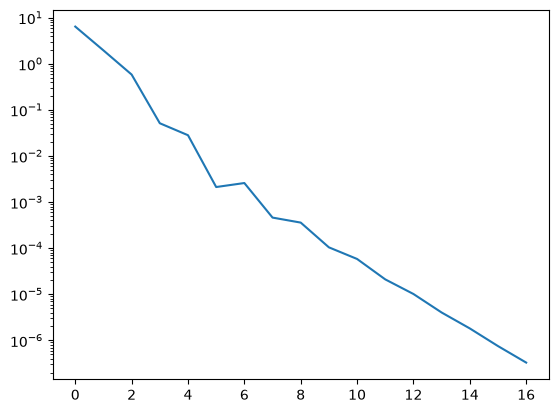

In [128]:
plt.semilogy(np.abs(error)) 

# VI Inverse Power iteration


What if we are interested in the smaller eigenvalue in magnitude?

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. What would be an eigenvalue of  ${\bf A}^{-1}$?


$${\bf A}^{-1}{\bf A}{\bf x}  = {\bf A}^{-1}\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \lambda {\bf A}^{-1} {\bf x}$$

$$\frac{1}{\lambda}{\bf x}  =  {\bf A}^{-1} {\bf x}$$


**Hence $\frac{1}{\lambda}$ is an eigenvalue of ${\bf A}^{-1} $**.

If we want to find the smallest eigenvalue in magnitude of ${\bf A}$, we can perform power iteration using the matrix ${\bf A}^{-1}$ to find $\bar\lambda = \frac{1}{\lambda}$, where  $\bar\lambda$ is the largest eigenvalue of ${\bf A}^{-1}$. (Power method with $A^{-1}$ will converge $|\frac{1}{\lambda _n}|$)

Let's implement that:

In [129]:
n = 4
D = np.diag([5,-1,2,7])

A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eig_index_sort
eigpos = eig_index_sort[0]

print(eigv[:,eigpos])

[-0.32049037+0.j  0.13005879+0.j  0.89693692+0.j -0.27545381+0.j]


In [130]:
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm

for i in range(20):
    x = la.inv(A)@x
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x) 

lambdan =  -0.9999999999978724
un =  [ 0.32049059 -0.13005934 -0.8969366   0.27545432]


Can you find ways to improve the code snippet above? 

In [131]:
#Inverse Power iteration to get smallest eigenvalue
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
P, L, Um = sla.lu(A)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  -0.999999999846632
un =  [ 0.32049224 -0.13006346 -0.89693424  0.27545814]


$x_{k+1} = A^{-1} x_k \Rightarrow A x_{k+1} = x_k$ solve for $x_{k+1}$
1) Factorize $A = PLU$ complexity: $O(n^3)$
2) solve for $Ly = b$ complexity: $O(n^2)$
3) solve for $Ux = y$ complexity: $O(n^2)$

# VII Inverse Shifted Power Iteration


What if we want to find another eigenvalue that is not the largest or the smallest? 

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. We want to find the eigenvalues of the shifted inverse matrix $({\bf A} - \sigma{\bf I})^{-1}$


$$({\bf A} - \sigma{\bf I})^{-1}{\bf x}  = \bar\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \bar\lambda ({\bf A} - \sigma{\bf I}) {\bf x} = \bar\lambda ({\lambda \bf I} - \sigma{\bf I}) {\bf x}$$

$$  \bar\lambda  = \frac{1}{\lambda-\sigma}$$


We could write the above eigenvalue problem as 


$$ {\bf B}^{-1}{\bf x}  = \bar\lambda {\bf x}$$

which can be solved by inverse power iteration, which will converge to the eigenvalue $\frac{1}{\lambda-\sigma}$

That is to say, we can use this method to find the eigenvalue that is closest to $\sigma$

In [132]:
n = 4
D = np.diag([5,-7,2,10])

A = U@D@U.T
eigl, eigv = la.eig(A)

print(eigl)
eigv

[-7.+0.j 10.+0.j  2.+0.j  5.+0.j]


array([[-0.32049037+0.j,  0.81718271+0.j,  0.26111924+0.j,
         0.40164049+0.j],
       [ 0.13005879+0.j, -0.10374229+0.j, -0.65265255+0.j,
         0.73916635+0.j],
       [ 0.89693692+0.j,  0.13816726+0.j,  0.37377092+0.j,
         0.19159666+0.j],
       [-0.27545381+0.j, -0.54987249+0.j,  0.60510883+0.j,
         0.50557764+0.j]])

In [133]:
#Shifted Inverse Power iteration 
sigma = 1

x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
B = A - sigma*np.eye(n)
P, L, Um = sla.lu(B)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  1.9999999999999996
un =  [ 0.26111924 -0.65265255  0.37377092  0.60510883]


# VIII Computational cost and convergence


- power iteration: to obtain largest eigenvalue in magnitude ${\lambda_1}$
    - Matrix-vector multiplications at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_2}{\lambda_1} \right|$
    
   
- inverse power iteration: to obtain smallest eigenvalue in magnitude ${\lambda_n}$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_n}{\lambda_{n-1}} \right|$  
    
   
- inverse shifted power iteration: to obtain an eigenvalue close to a known/given value $\sigma$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_c - \sigma}{\lambda_{c2} - \sigma} \right|$  
    where $\lambda_c$ is the closest eigenvalue to $\sigma$ and $\lambda_{c2}$ is the second closest eigenvalue to $\sigma$.